Importing dataset and library

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "covid_19_indonesia_time_series_all.csv"
dataset_handler = "hendratno/covid19-indonesia"

df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS, dataset_handler, file_path,
)

df.head()



/tmp/ipykernel_3073/3426952953.py:12: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'covid19-indonesia' dataset.


,Date,Location ISO Code,Location,New Cases,New Deaths,New Recovered,New Active Cases,Total Cases,Total Deaths,Total Recovered,...,Latitude,New Cases per Million,Total Cases per Million,New Deaths per Million,Total Deaths per Million,Total Deaths per 100rb,Case Fatality Rate,Case Recovered Rate,Growth Factor of New Cases,Growth Factor of New Deaths
0,3/1/2020,ID-JK,DKI Jakarta,2,0,0,2,39,20,75,...,-6.204699,0.18,3.60,0.0,1.84,0.18,51.28%,192.31%,NaN,NaN
1,3/2/2020,ID-JK,DKI Jakarta,2,0,0,2,41,20,75,...,-6.204699,0.18,3.78,0.0,1.84,0.18,48.78%,182.93%,1.0,1.0
2,3/2/2020,IDN,Indonesia,2,0,0,2,2,0,0,...,-0.789275,0.01,0.01,0.0,0.00,0.00,0.00%,0.00%,NaN,NaN
3,3/2/2020,ID-RI,Riau,1,0,0,1,1,0,1,...,0.511648,0.16,0.16,0.0,0.00,0.00,0.00%,100.00%,NaN,NaN
4,3/3/2020,ID-JK,DKI Jakarta,2,0,0,2,43,20,75,...,-6.204699,0.18,3.96,0.0,1.84,0.18,46.51%,174.42%,1.0,1.0


Data Cleaning

In [ ]:
df.isna().sum()

,0
Date,0
Location ISO Code,0
Location,0
New Cases,0
New Deaths,0
New Recovered,0
New Active Cases,0
Total Cases,0
Total Deaths,0
Total Recovered,0


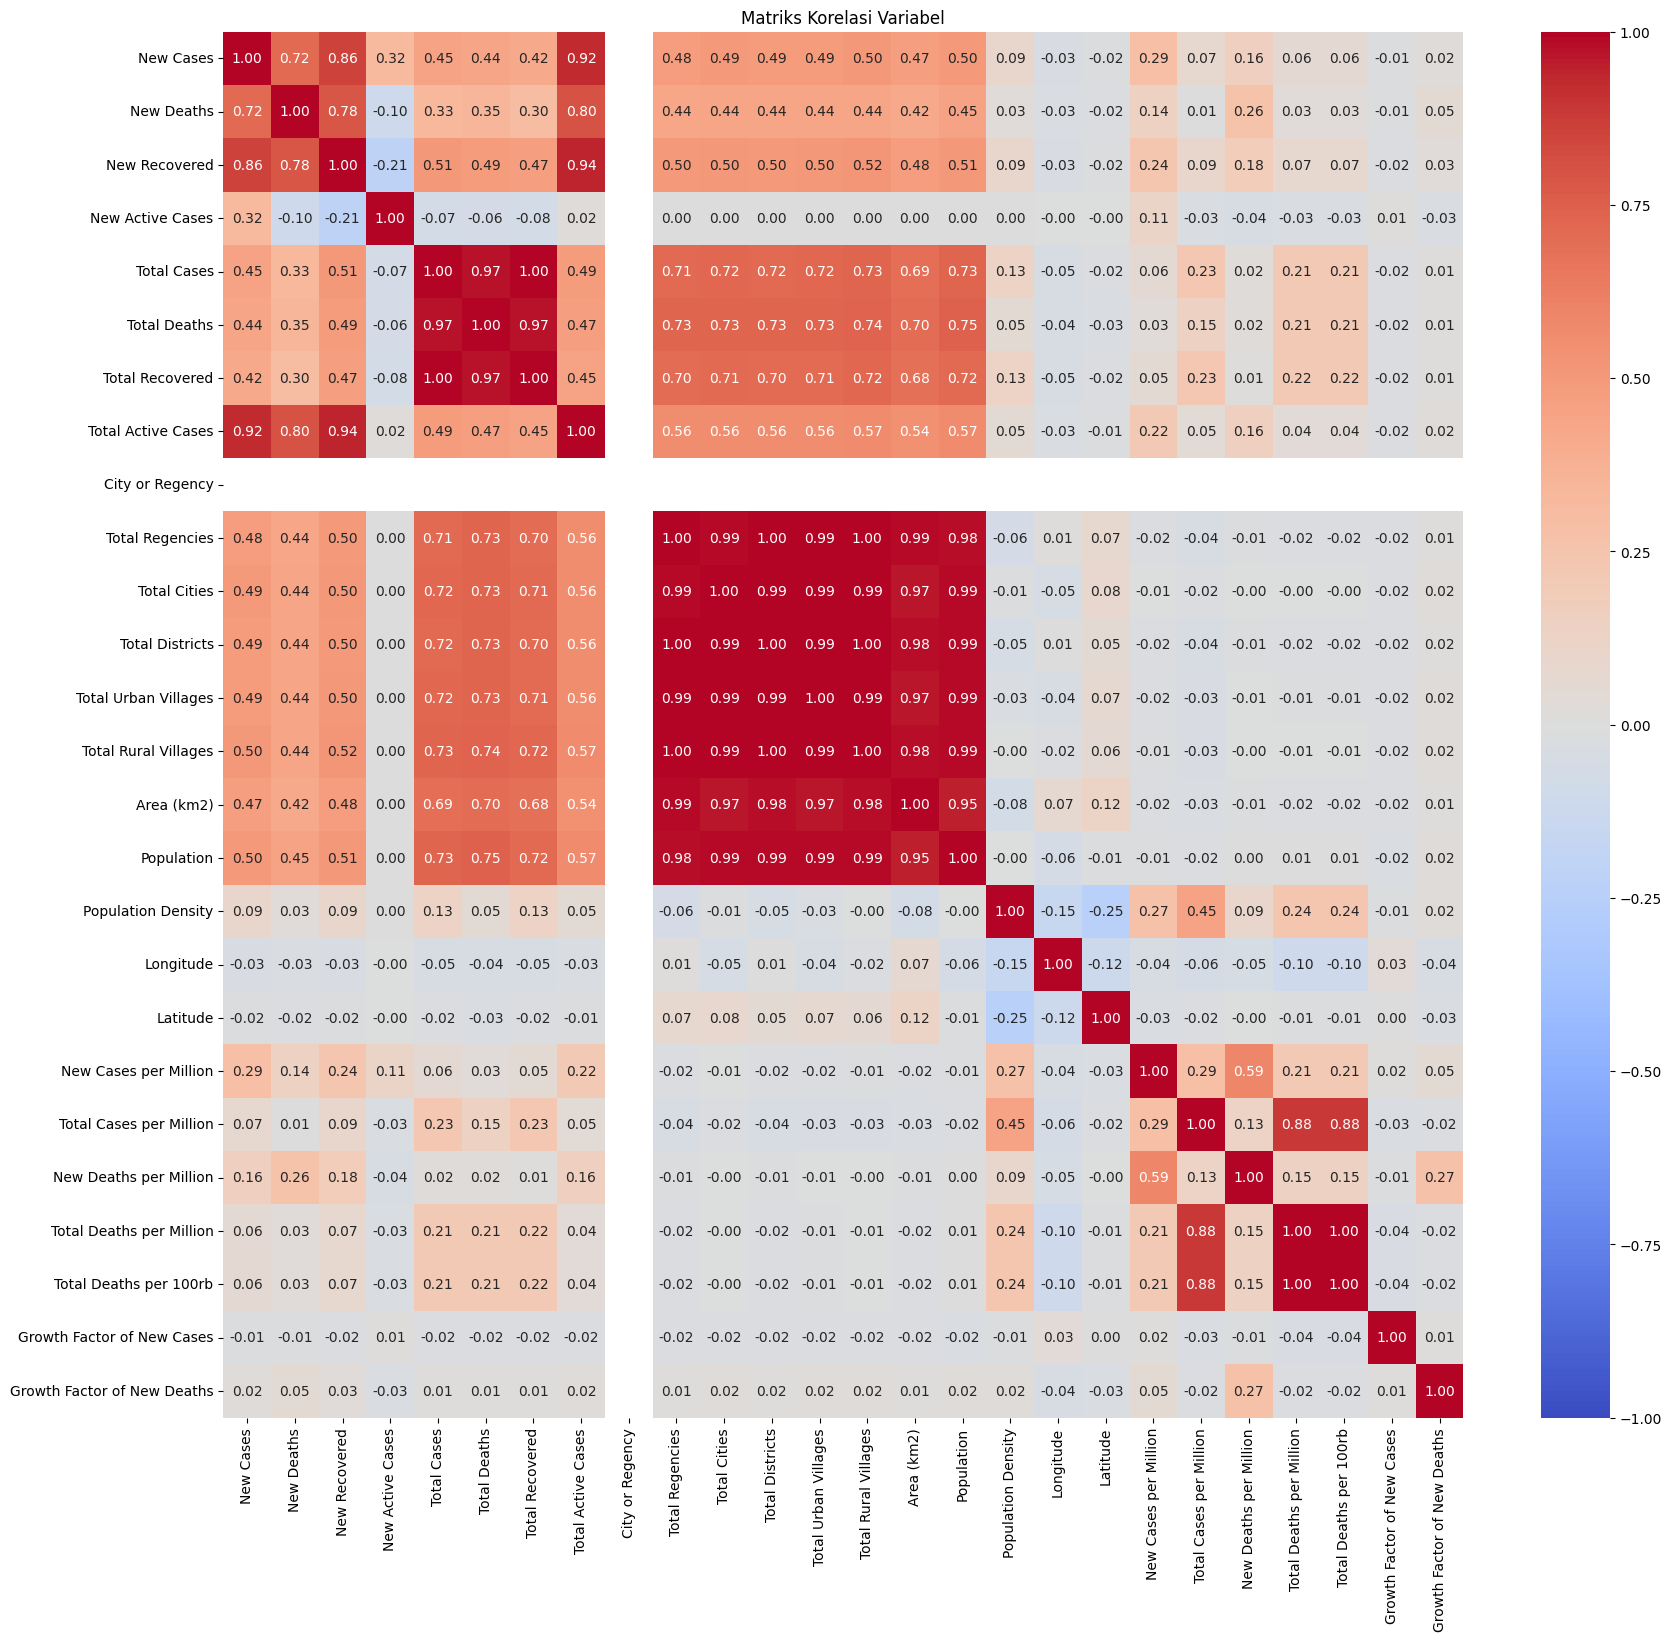

In [ ]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(20, 18))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Matriks Korelasi Variabel')
plt.show()

In [ ]:
drop_columns = ['City or Regency', 'Special Status', 'Total Cities', 'Total Regencies', 'Total Districts', 'Total Urban Villages', 'Total Rural Villages', 'Growth Factor of New Cases', 'Growth Factor of New Deaths', 'Latitude', 'Longitude', 'Time Zone', 'Province']

df = df.drop(columns=drop_columns, errors='ignore')

df['Case Fatality Rate'] = df['Case Fatality Rate'].str.rstrip('%')
df['Case Fatality Rate'] = df['Case Fatality Rate'].astype(float)

df.loc[df['Location'] == 'Indonesia', 'Island'] = 'Nasional'

In [ ]:
df.isna().sum()

,0
Date,0
Location ISO Code,0
Location,0
New Cases,0
New Deaths,0
New Recovered,0
New Active Cases,0
Total Cases,0
Total Deaths,0
Total Recovered,0


Data Visualization

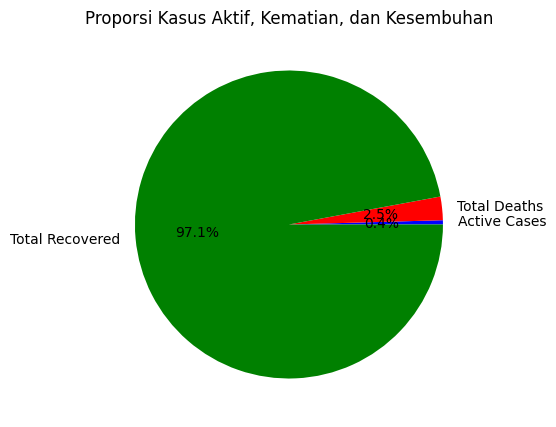

In [ ]:
cases = df['Total Cases'].max()
deaths = df['Total Deaths'].max()
recovered = df['Total Recovered'].max()
active = cases - (deaths + recovered)  # Menghitung sisa kasus aktif

categories = ['Active Cases', 'Total Deaths', 'Total Recovered']
values = [active, deaths, recovered]

plt.figure(figsize=(8, 5))
# Urutan yang benar: values dulu, baru labels=...
plt.pie(values, labels=categories, colors=['blue', 'red', 'green'], autopct='%1.1f%%')
plt.title('Proporsi Kasus Aktif, Kematian, dan Kesembuhan')
plt.show()


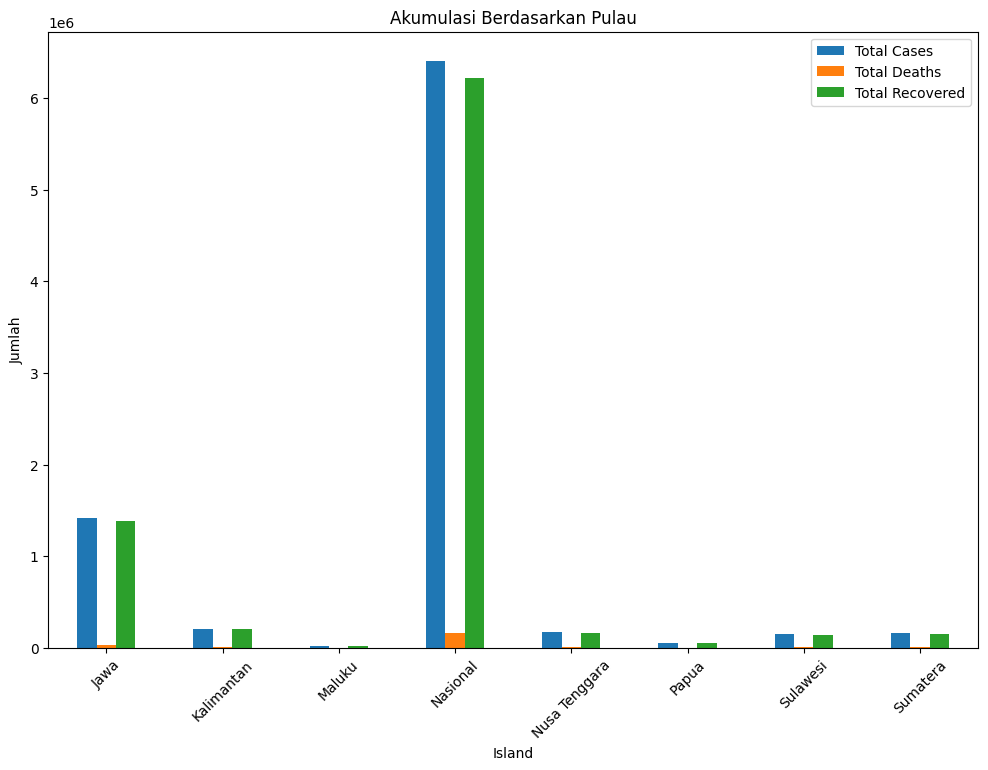

In [ ]:
df.groupby('Island')[['Total Cases', 'Total Deaths', 'Total Recovered']].max().plot(kind='bar', figsize=(12, 8))

plt.title('Akumulasi Berdasarkan Pulau')
plt.ylabel('Jumlah')
plt.xticks(rotation=45)
plt.show()

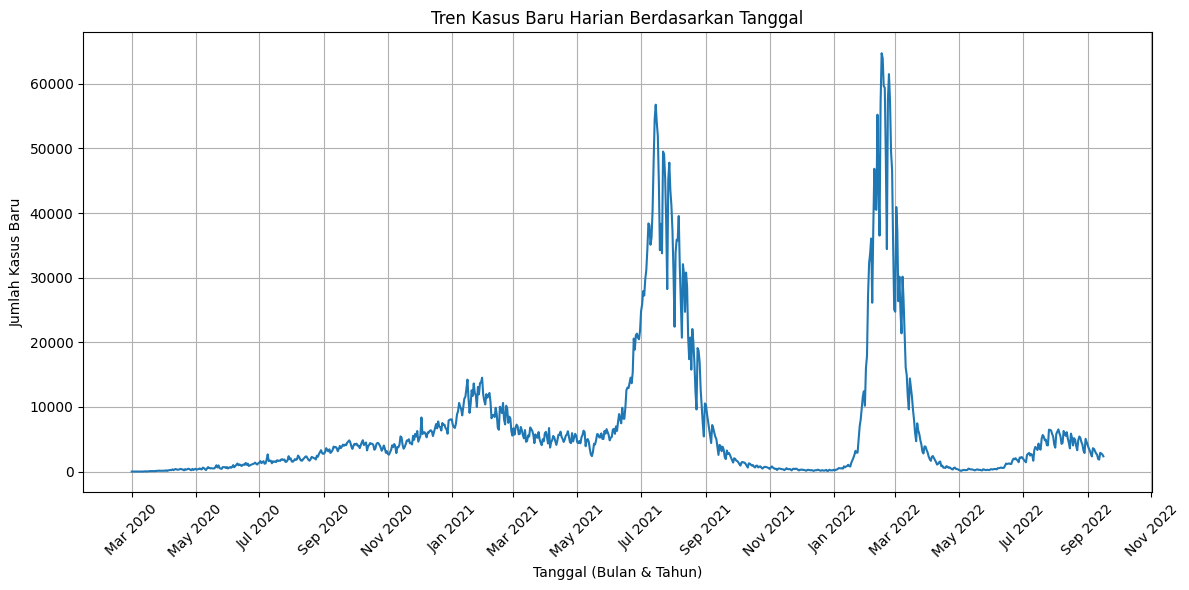

In [ ]:
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date')
daily_cases = df.groupby('Date')['New Cases'].max()

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(daily_cases.index, daily_cases.values, color='tab:blue')

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

plt.xticks(rotation=45)

plt.title('Tren Kasus Baru Harian Berdasarkan Tanggal')
plt.xlabel('Tanggal (Bulan & Tahun)')
plt.ylabel('Jumlah Kasus Baru')
plt.grid(True)
plt.tight_layout()
plt.show()

Create Model (Linear Regression)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

X = df[['Total Cases', 'Population Density']]
y = df['Total Deaths']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Koefisien (bobot tiap fitur):", model.coef_)
print("Intercept (titik potong):", model.intercept_)
print("Mean Squared Error (MSE):", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

Koefisien (bobot tiap fitur): [ 0.02764338 -0.49772367  0.12541685]
Intercept (titik potong): 517.9037332073904
Mean Squared Error (MSE): 15547760.462757794
R2 Score: 0.9483007010661729


Evaluate Model

R2 Train: 0.9498 | R2 Test: 0.9483


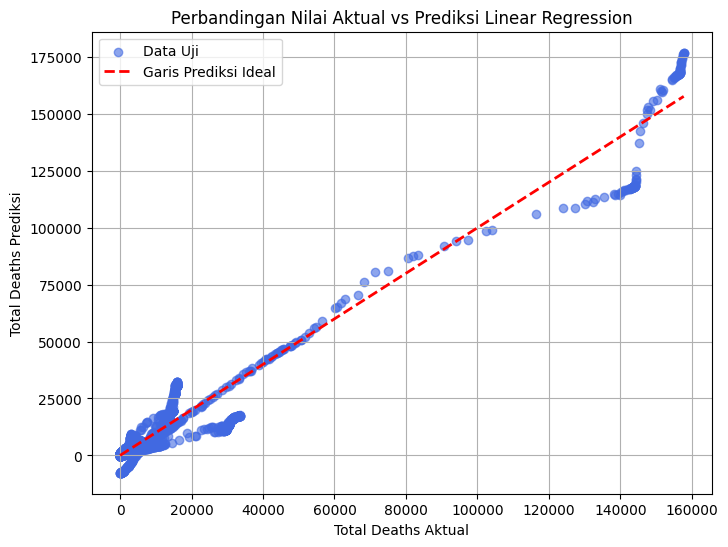

ValueError: The feature names should match those that were passed during fit.
Feature names seen at fit time, yet now missing:
- New Active Cases


In [ ]:
import joblib

r2_train = model.score(X_train, y_train)
r2_test = model.score(X_test, y_test)
print(f"R2 Train: {r2_train:.4f} | R2 Test: {r2_test:.4f}")

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6, color='royalblue', label='Data Uji')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Garis Prediksi Ideal')
plt.xlabel('Total Deaths Aktual')
plt.ylabel('Total Deaths Prediksi')
plt.title('Perbandingan Nilai Aktual vs Prediksi Linear Regression')
plt.legend()
plt.grid(True)
plt.show()

data_baru = pd.DataFrame({
    'Total Cases': list((50000, 150000, 300000)),
    'Population Density': list((150, 1500, 5000))
})
prediksi_baru = model.predict(data_baru)
for i, pred in enumerate(prediksi_baru):
    print(f"Skenario {i+1} -> Prediksi Total Deaths: {pred:.0f} jiwa")

joblib.dump(model, 'model_covid_linear_regression.joblib')
